# F3-Z4, F5-Z4 and F7-Z2: what can we confidently report?

Focused diagnostic companion to `bq2_ac.ipynb`, using the same **July–August 2018/2019** window and both input versions. Earlier screen/audit output folders are preserved.

| Zone | Confident finding in the recorded data | Interpretation to retain |
|---|---|---|
| **F3-Z4** | More time above the AC-on threshold and higher power while on both contribute to increased energy. Below-threshold time inside common business-hour windows falls. | A metered operating-pattern change is supported. Its cause and the environmental baseline shift remain unresolved. |
| **F5-Z4** | On-power rises from about **15.1 to 20.1 kW**, with runtime near **7.45 h/day** in both years. About **99%** of the unadjusted energy difference is an on-power contribution. | Inspect controls, load/equipment and metering changes. Neither verified overcooling nor degradation can be inferred. |
| **F7-Z2** | Under matched conditions, recorded sustained-on moisture remains about **1.15 g/kg higher**, with little on-power change. The temperature/moisture association between on and night states also changes. | A possible performance/control issue remains a lead. Sensor changes, ventilation and internal moisture remain competing explanations. |

**No mechanical degradation is confirmed.** Observation confidence is higher than confidence in the cause. A major sensor-comparability caveat emerges from the original dataset documentation and the inactive-state checks below.


## Evidence and methods

### External context that changes interpretation

The [original dataset paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC7371880/) documents ceiling-mounted sensors, removal for a firmware update between September 2018 and March 2019, and nominal sensor design accuracies of ±0.4°C and ±2 RH percentage points. It does not establish unchanged calibration or exact local placement across our two periods. The accuracy scenarios below are assumptions, not measured errors or probabilistic intervals.

### Diagnostic rules

- Preserve the screen's `with_fills` and `without_fills` definitions and frozen 2018 zone-specific AC-on thresholds. Full-day energy still requires all 1,440 AC-plus-plug minutes. No new filling or partial-day scaling.
- Decompose **unadjusted** mean daily electricity on all 2018 reference days versus the screen's supported 2019 days. With `H` = mean on-hours, `P` = pooled on-energy / on-hours and `O` = mean below-threshold energy, `E = H × P + O`. Symmetric runtime/power contributions sum exactly to the observed change. They are accounting terms, not causal effects or the earlier weather-model residual.
- Record schedules separately. Shared interior windows are 08:00–11:00 and 13:15–16:15. Below-threshold time there is an electrical-operation proxy, not a verified compressor-cycle classification.
- State comparisons use full joint AC/temperature/RH/plug hours. **Steady-on** hours are 09, 10, 14 or 15 after 120 continuous minutes above the on threshold. **Night-off** hours are 02–05 after 120 continuous minutes below it, on inferred working days.
- The additional **long-off control** uses 02–05 after at least 24 continuous hours of valid AC readings **≤0.1 kW**, including weekends/closures. It overlaps other states and is not independent replication. Missing power interrupts continuity.
- Match each 2019 hour to 2018 hours of the same clock hour and operating state, with outdoor temperature within 1°C, outdoor humidity ratio within 1 g/kg, and plug power within `max(0.1 kW, 20% of that 2018 state median)`. Use all candidates, requiring at least three distinct reference dates. No indoor outcome determines matching. Sensitivities halve or multiply all calipers by 1.5.
- Balance evaluation days equally. A displayed matched change needs 10 evaluation days, 10 used reference days, and four calendar weeks in both years. **These new matched results are descriptive, with no newly fitted causal model or inferential intervals.** Earlier screen intervals remain conditional, nominal and unadjusted for multiple screening.
- Same-day on-minus-night contrasts compare the recorded associations across years. Constant additive offsets in temperature or RH cancel from the corresponding contrast, but state-dependent errors, sensor movement/gain, different thermal/moisture loads and nonlinear humidity-ratio effects do not. This is not a causal difference-in-differences design.
- Recompute F7-Z2 humidity ratio from minute T/RH for sensor scenarios while holding outdoor/activity matching fixed. Opposing year-specific design-error scenarios are deliberately extreme; a stable shared bias is also tested. Do not interpret their range as a confidence interval.

Regional ERA5 weather, inferred working-day/activity labels and unknown clock alignment limit matching. Thermostat settings, occupancy, airflow, cooling output, calibration history and maintenance/fault outcomes remain unavailable. Local peer medians are context only, with their own missingness and different operating conditions.


In [1]:
from pathlib import Path
import json
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Locate this checkout from the repository root or any notebook subfolder.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "AGENTS.md").is_file()
                 and (p / "mould-ac-degradation/bq2_utils.ipynb").is_file())
analysis_dir = repo_root / "mould-ac-degradation"
sys.path.insert(0, str(analysis_dir / "src"))
RUN_CHECKS = False
helper_notebook = analysis_dir / "bq2_utils.ipynb"
get_ipython().run_line_magic("run", f'-i "{helper_notebook}"')

from bq2 import case_investigation as case
from bq2 import zone_screen as screen
sys.path.insert(0, str(repo_root / "baseline"))
from humidity_risk_baseline import load_bangkok_era5_weather
output_dir = Path(analysis_dir / "outputs/bq2-case-investigation")
output_dir.mkdir(parents=True, exist_ok=True)
protected = [p for folder in [analysis_dir / "outputs/f3z1-input-audit", analysis_dir / "outputs/f3z1-first-pass", analysis_dir / "outputs/bq2-zone-screen"]
             for p in Path(folder).glob("*") if p.is_file()]
previous_hashes = {str(p): screen.digest(p) for p in protected}
for item in json.loads(Path(analysis_dir / "outputs/bq2-zone-screen/input_manifest.json").read_text()):
    assert screen.digest(repo_root / item["path"]) == item["sha256"]
weather = load_bangkok_era5_weather(repo_root / "baseline/data/bangkok_era5_hourly_2018-2019.csv")
helpers = {n: globals()[n] for n in ["add_outdoor_psychrometrics", "humidity_ratio_gkg", "ac_on_threshold"]}
pd.set_option("display.max_columns", 14)


## 1. Rebuild the focused inputs and reproduce the prior electricity cohorts

Sensors and local peers are read from the original and cleaned floor files using explicit date formats. Invalid/missing data cannot create a continuous active or inactive run.


In [2]:
data = case.build_case_tables(repo_root, weather, helpers, output_dir)
predictions = pd.read_csv(analysis_dir / "outputs/bq2-zone-screen/predictions.csv", parse_dates=["time"])
decomposition = case.energy_decomposition(data["daily"], predictions, output_dir)
display(decomposition[["zone_id", "variant", "reference_days", "evaluation_days",
                       "on_hours_2018", "on_hours_2019", "on_power_2018", "on_power_2019",
                       "power_share_of_change_pct"]].rename(columns={
                           "reference_days": "2018 days", "evaluation_days": "2019 days",
                           "on_hours_2018": "2018 on h/day", "on_hours_2019": "2019 on h/day",
                           "on_power_2018": "2018 on kW", "on_power_2019": "2019 on kW",
                           "power_share_of_change_pct": "Power contribution (%)"}).round(3))
display(data["sensor_checks"].round(3))
# Independent reconciliation against the screen's saved daily target, not the decomposition formula.
old = pd.read_csv(analysis_dir / "outputs/bq2-zone-screen/daily_features.csv", parse_dates=["time"])
old = old[old.eligible & old.zone_id.isin(["F3-Z4", "F5-Z4", "F7-Z2"])]
joined = data["daily"].merge(old[["zone_id", "variant", "time", "ac_kWh"]],
    left_on=["zone_id", "variant", "date"], right_on=["zone_id", "variant", "time"], validate="one_to_one", suffixes=("_new", "_old"))
assert len(joined) == len(data["daily"])
np.testing.assert_allclose(joined.ac_kWh_new, joined.ac_kWh_old, atol=1e-9)


F3-Z4: case inputs and operating-state features built


F5-Z4: case inputs and operating-state features built


F7-Z2: case inputs and operating-state features built


,zone_id,variant,2018 days,2019 days,2018 on h/day,2019 on h/day,2018 on kW,2019 on kW,Power contribution (%)
0,F3-Z4,with_fills,41,22,6.753,7.241,19.386,20.591,49.485
1,F3-Z4,without_fills,41,10,6.753,7.267,19.386,20.782,51.859
2,F5-Z4,with_fills,41,23,7.448,7.464,15.130,20.096,99.368
3,F5-Z4,without_fills,41,23,7.448,7.464,15.130,20.096,99.368
4,F7-Z2,with_fills,41,20,8.467,8.011,25.717,25.814,-7.285
5,F7-Z2,without_fills,39,14,8.492,8.026,25.704,25.621,5.419


,zone_id,stream,max_constant_minutes,largest_minute_change,p999_minute_change,largest_change_time
0,F3-Z4,temperature,46,1.25,0.847,2019-07-03 13:07:00
1,F3-Z4,RH,20,8.22,2.097,2019-08-13 10:12:00
2,F3-Z4,paired,17,1.25,0.847,2019-07-03 13:07:00
3,F5-Z4,temperature,55,1.15,0.870,2019-08-05 13:09:00
4,F5-Z4,RH,23,4.85,2.320,2019-08-16 13:04:00
5,F5-Z4,paired,21,1.15,0.870,2019-08-05 13:09:00
6,F7-Z2,temperature,58,1.13,0.800,2019-07-30 13:06:00
7,F7-Z2,RH,18,5.22,2.390,2019-08-10 17:18:00
8,F7-Z2,paired,16,1.13,0.800,2019-07-30 13:06:00


### Electrical changes we can report

- **F3-Z4:** mean on-time rises from 6.75 to 7.24/7.27 h/day, and pooled on-power from 19.39 to 20.59/20.78 kW, with/without fills. Inside fixed business-hour windows, below-threshold time falls from about 25 minutes/day to roughly 1/0 minute. Median morning/lunch/evening transitions move only a few minutes. This supports more continuous electrical operation, rather than a large extension of the normal start/stop schedule.
- **F5-Z4:** on-time is essentially unchanged (7.45 versus 7.46 h/day). Higher on-power contributes about 37.0 kWh of the 37.3 kWh unadjusted difference, about 99.4%. This arithmetic does not identify a thermostat change, new equipment, extra cooling demand, metering change or an efficiency loss.
- **F7-Z2:** the usual on-time median is about 7.98 hours in both periods. Eight 2018 reference days exceed nine on-hours, versus none in the supported 2019 cohort. Fewer extended days explain much of the lower mean runtime; it is not evidence of a shorter routine schedule. On-power remains near 25.7 kW.

The earlier weather-reference departures remain historical screening results. These decompositions explain a different quantity: raw energy on the stated cohorts. They must not be presented as causal shares of the weather-adjusted residual.


In [3]:
matching = case.matched_states(data["hourly"], output_dir)
primary = matching["matched_states"].query("specification == 'primary'")
display(primary[primary.metric.isin(["ac_kW", "temp_C", "indoor_w_gkg"])].pivot(
    index=["zone_id", "state", "variant", "matched_days"], columns="metric", values="mean_change").round(3))
contrasts = case.state_contrasts(matching["matched_details"], output_dir)
display(contrasts.query("minimum_hours_each_state == 1").round(3))
context = case.profiles_and_persistence(data, matching, output_dir)
schedule = context["event_schedule"].query("variant == 'with_fills'").copy()
schedule["transition"] = schedule.session + " " + schedule.event
schedule = schedule[schedule.transition.isin(["morning start", "lunch stop", "lunch start", "evening stop"])]
schedule = schedule.pivot(index=["zone_id", "year"], columns="transition", values="median")
def clock_label(value):
    minute = int(round(value * 60))
    return f"{minute // 60:02d}:{minute % 60:02d}"
display(schedule.apply(lambda col: col.map(clock_label)))


metric                                        ac_kW  indoor_w_gkg  temp_C
zone_id state     variant       matched_days                             
F3-Z4   long_off  with_fills    18            0.000        -0.615  -2.654
                  without_fills 16            0.000        -1.005  -2.981
        night_off with_fills    40            0.000        -0.653  -2.855
                  without_fills 40            0.000        -0.793  -2.900
        steady_on with_fills    37            1.547        -0.976  -3.517
                  without_fills 24            0.250        -0.892  -3.455
F5-Z4   long_off  with_fills    16            0.000        -1.352  -2.664
                  without_fills 16            0.000        -1.660  -2.862
        night_off with_fills    40            0.000        -1.233  -2.727
                  without_fills 37            0.000        -1.139  -2.659
        steady_on with_fills    26            5.517        -1.325  -3.909
                  without_fills 15            5.887        -1.289  -3.985
F7-Z2   long_off  with_fills    12            0.000         0.152  -1.528
                  without_fills 10            0.000         0.378  -1.511
        night_off with_fills    39            0.000         0.208  -1.489
                  without_fills 39            0.000         0.239  -1.382
        steady_on with_fills    37            0.020         1.150  -0.446
                  without_fills 31           -0.172         1.164  -0.558

,zone_id,variant,minimum_hours_each_state,paired_days,metric,reportable,change_in_on_minus_night_contrast,median_change_in_contrast
0,F3-Z4,with_fills,1,37,temp_C,True,-0.602,-0.099
1,F3-Z4,with_fills,1,37,rh_pct,True,-1.228,-0.521
2,F3-Z4,with_fills,1,37,indoor_w_gkg,True,-0.282,0.310
6,F3-Z4,without_fills,1,24,temp_C,True,-0.398,-0.002
7,F3-Z4,without_fills,1,24,rh_pct,True,-0.388,0.169
8,F3-Z4,without_fills,1,24,indoor_w_gkg,True,0.045,0.503
12,F5-Z4,with_fills,1,26,temp_C,True,-0.971,-1.031
13,F5-Z4,with_fills,1,26,rh_pct,True,2.250,2.863
14,F5-Z4,with_fills,1,26,indoor_w_gkg,True,0.003,0.211
18,F5-Z4,without_fills,1,14,temp_C,True,-1.310,-1.224


transition   evening stop lunch start lunch stop morning start
zone_id year                                                  
F3-Z4   2018        16:30       12:59      11:31         07:45
        2019        16:34       13:03      11:35         07:49
F5-Z4   2018        16:27       13:00      11:45         07:45
        2019        16:30       13:03      11:49         07:48
F7-Z2   2018        16:54       12:55      11:39         07:40
        2019        16:57       12:58      11:42         07:42

## 2. Inactive-state controls change the temperature interpretation

F3-Z4 and F5-Z4 still record roughly **2.6–3.0°C lower temperatures** in 2019 during matched night hours after at least 24 hours of near-zero AC power. This persists without fills. The absolute temperature shift cannot be attributed wholly to active cooling by that zone. Sensor continuity, location, adjacent spaces and other ambient/thermal changes remain unresolved.

The same-day on-versus-night temperature association shows some additional change: about −0.4 to −0.6°C for F3-Z4 and −1.0 to −1.3°C for F5-Z4. F3-Z4's median contrast is near zero, so its mean should not be overinterpreted. F5-Z4's additional on-state cooling association is more consistent, but still does not measure delivered cooling or COP. Actual overcooling is unverified.

F7-Z2 shows the opposite state pattern: the on-minus-night temperature contrast rises about **1°C**, and its corresponding moisture contrast rises about **1 g/kg**, on 35/30 paired days with/without fills. Those recorded associations survive removal of a uniform additive temperature/RH offset in the respective fields. Changed ventilation, internal moisture, thermal loads, sensor response or controls can also produce them; they do not establish an AC fault.


In [4]:
sensitivity = case.sensor_sensitivity(data["hourly"], data["sensor_scenarios"], output_dir)
display(sensitivity[sensitivity.state.eq("steady_on") & sensitivity.scenario.isin([
    "as_recorded", "opposing_nominal_errors_min", "opposing_nominal_errors_max", "same_nominal_low_both_years"])].round(3))
display(matching["matched_states"].query(
    "zone_id == 'F7-Z2' and state == 'steady_on' and metric == 'indoor_w_gkg'")[
    ["variant", "specification", "matched_days", "mean_change", "reportable"]].round(3))
display(context["monthly_matched_changes"].query("zone_id == 'F7-Z2' and state == 'steady_on'").round(3))


,zone_id,variant,state,scenario,matched_hours,matched_days,moisture_change_gkg
18,F7-Z2,with_fills,steady_on,as_recorded,116,37,1.150
19,F7-Z2,with_fills,steady_on,opposing_nominal_errors_min,116,37,-0.022
20,F7-Z2,with_fills,steady_on,opposing_nominal_errors_max,116,37,2.322
21,F7-Z2,with_fills,steady_on,same_nominal_low_both_years,116,37,1.128
45,F7-Z2,without_fills,steady_on,as_recorded,87,31,1.164
46,F7-Z2,without_fills,steady_on,opposing_nominal_errors_min,87,31,-0.008
47,F7-Z2,without_fills,steady_on,opposing_nominal_errors_max,87,31,2.337
48,F7-Z2,without_fills,steady_on,same_nominal_low_both_years,87,31,1.144


,variant,specification,matched_days,mean_change,reportable
213,with_fills,primary,37,1.150,True
218,with_fills,tighter,20,1.053,True
223,with_fills,looser,41,1.218,True
258,without_fills,primary,31,1.164,True
263,without_fills,tighter,8,NaN,False
268,without_fills,looser,41,1.183,True


,zone_id,variant,state,month,matched_days,matched_hours,change_ac_kW,change_temp_C,change_rh_pct,change_indoor_w_gkg
28,F7-Z2,with_fills,steady_on,7,16,43,0.407,-0.159,8.334,1.270
29,F7-Z2,with_fills,steady_on,8,21,73,-0.275,-0.664,9.101,1.058
34,F7-Z2,without_fills,steady_on,7,11,29,-0.118,-0.364,9.239,1.293
35,F7-Z2,without_fills,steady_on,8,20,58,-0.202,-0.665,9.298,1.093


## 3. F7-Z2 remains a diagnostic lead, with a material measurement limit

The primary matched steady-on moisture increase is about **+1.15/+1.16 g/kg** with/without fills, from 37/31 evaluation days. Power changes little. The increase appears in July and August; the observed window does not establish progressive deterioration. Wider matching agrees in direction. The tighter observed-only specification has only eight days and is withheld under the reporting rule.

A 2019-only RH correction between six and eight percentage points would erase the absolute moisture difference in this scenario. A fixed low nominal bias shared by both years barely changes it. However, opposing year-specific errors within the paper's nominal T/RH design values can move the absolute difference to approximately zero. That is a worst-case sensitivity assumption, **not evidence that the sensors actually have those errors**, and not a confidence interval.

We can confidently report higher **recorded** moisture during sustained AC operation and a changed state association. We cannot yet report a verified physical loss of dehumidification. Calibration/continuity checks are essential before attributing the signal to equipment. The day-versus-night pattern means a single uniform offset is not a complete explanation either; state-dependent sensor effects and operating/environmental changes remain alternatives.


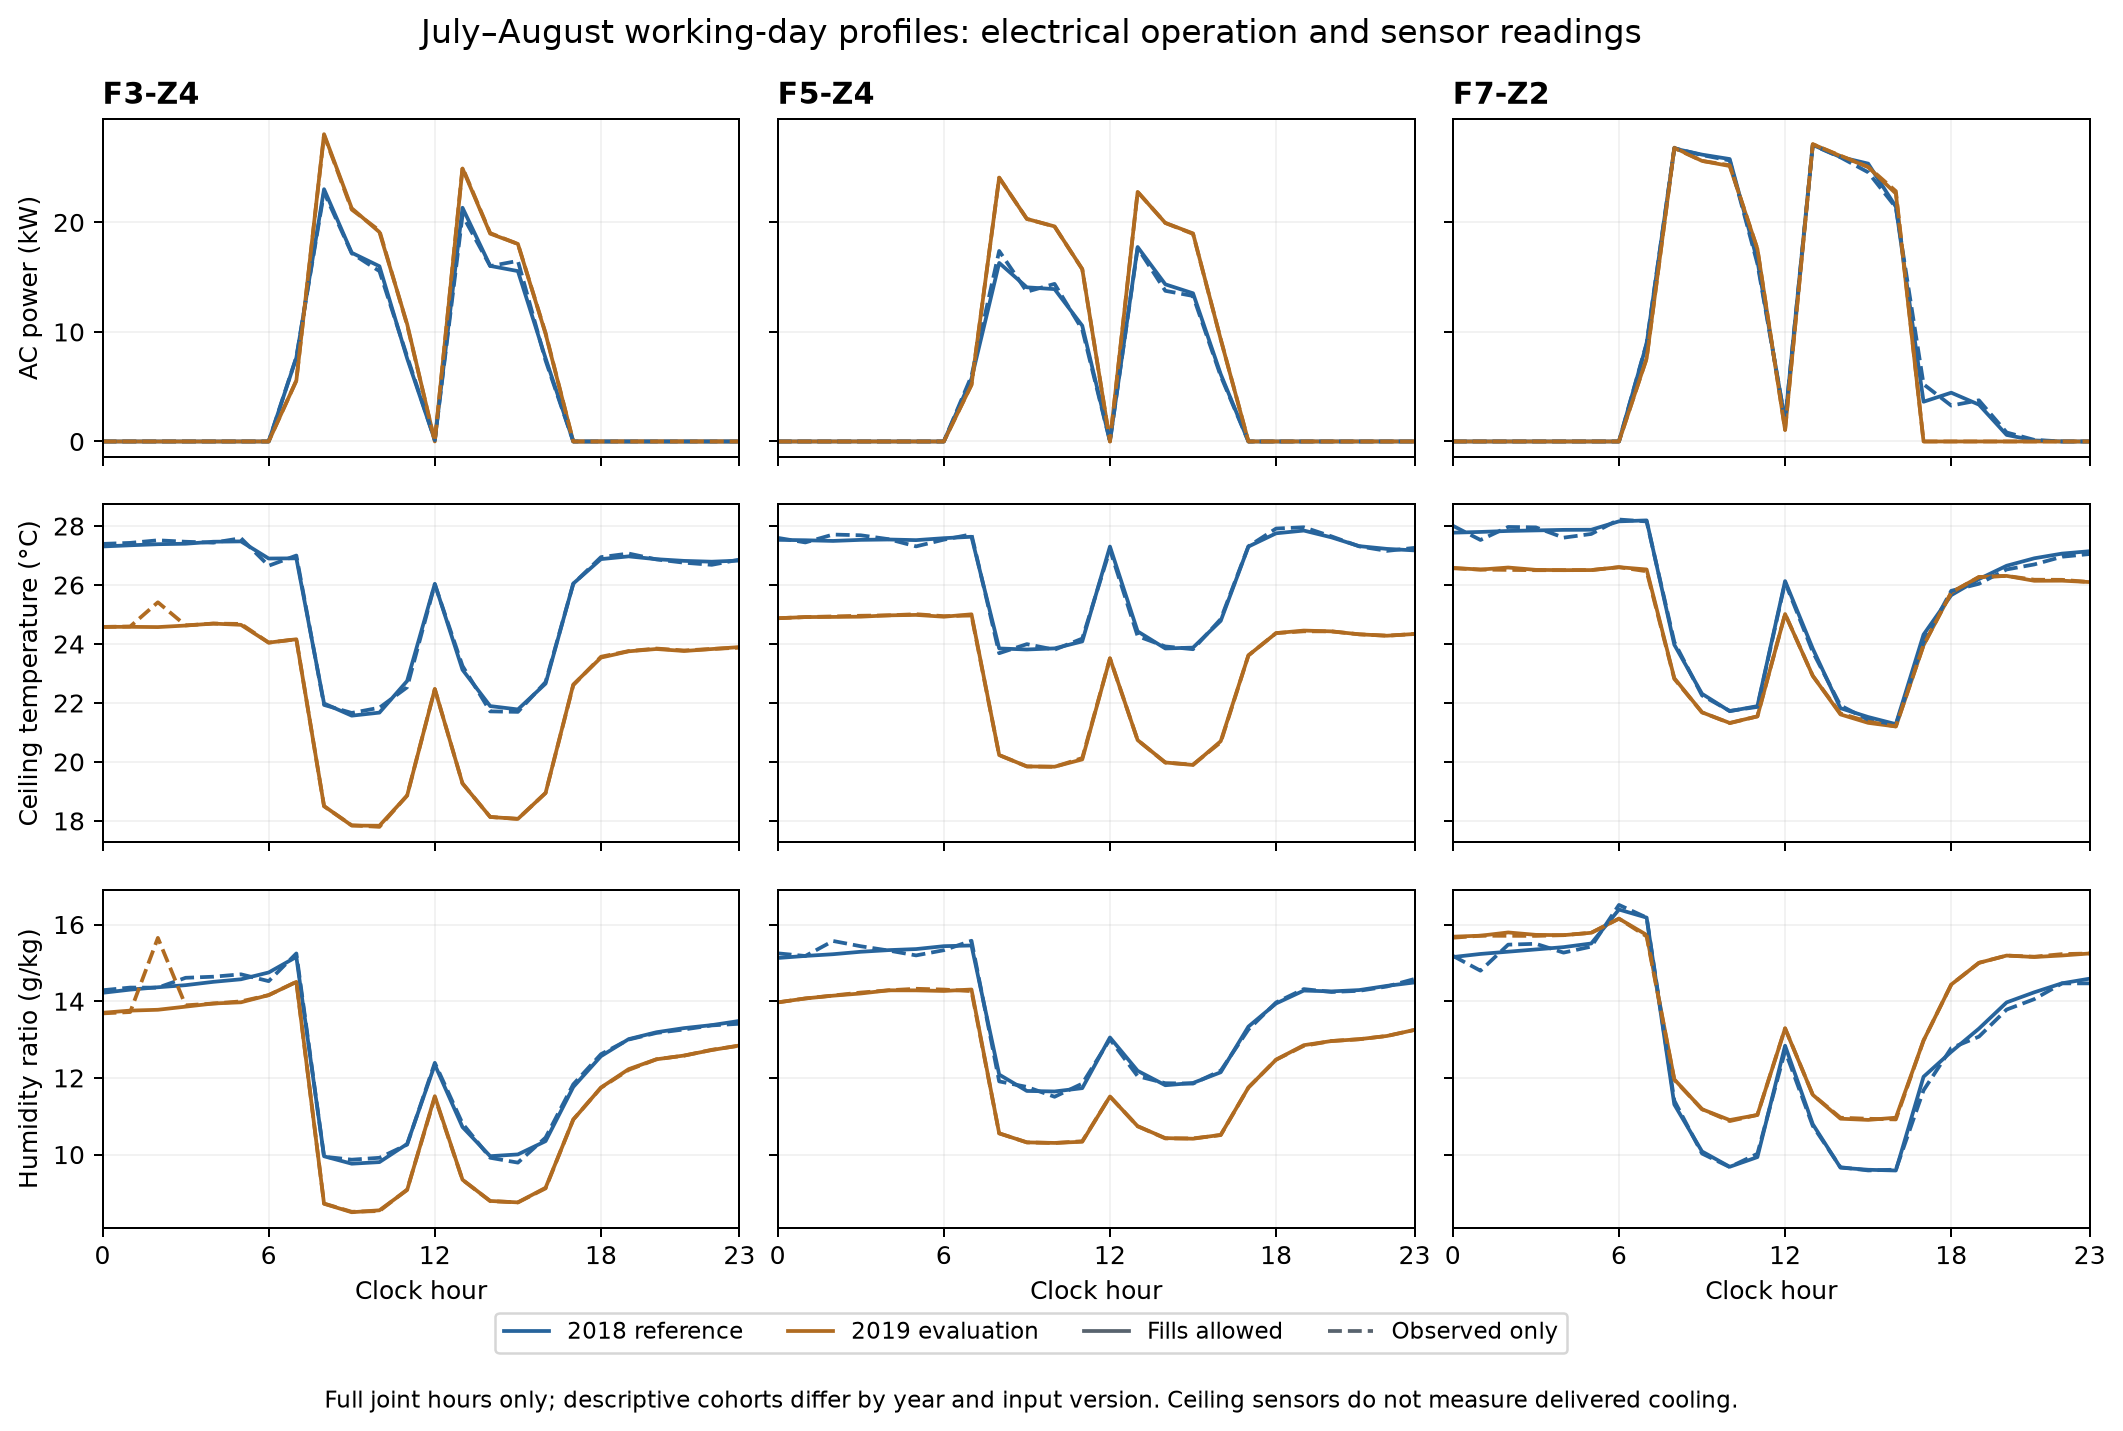

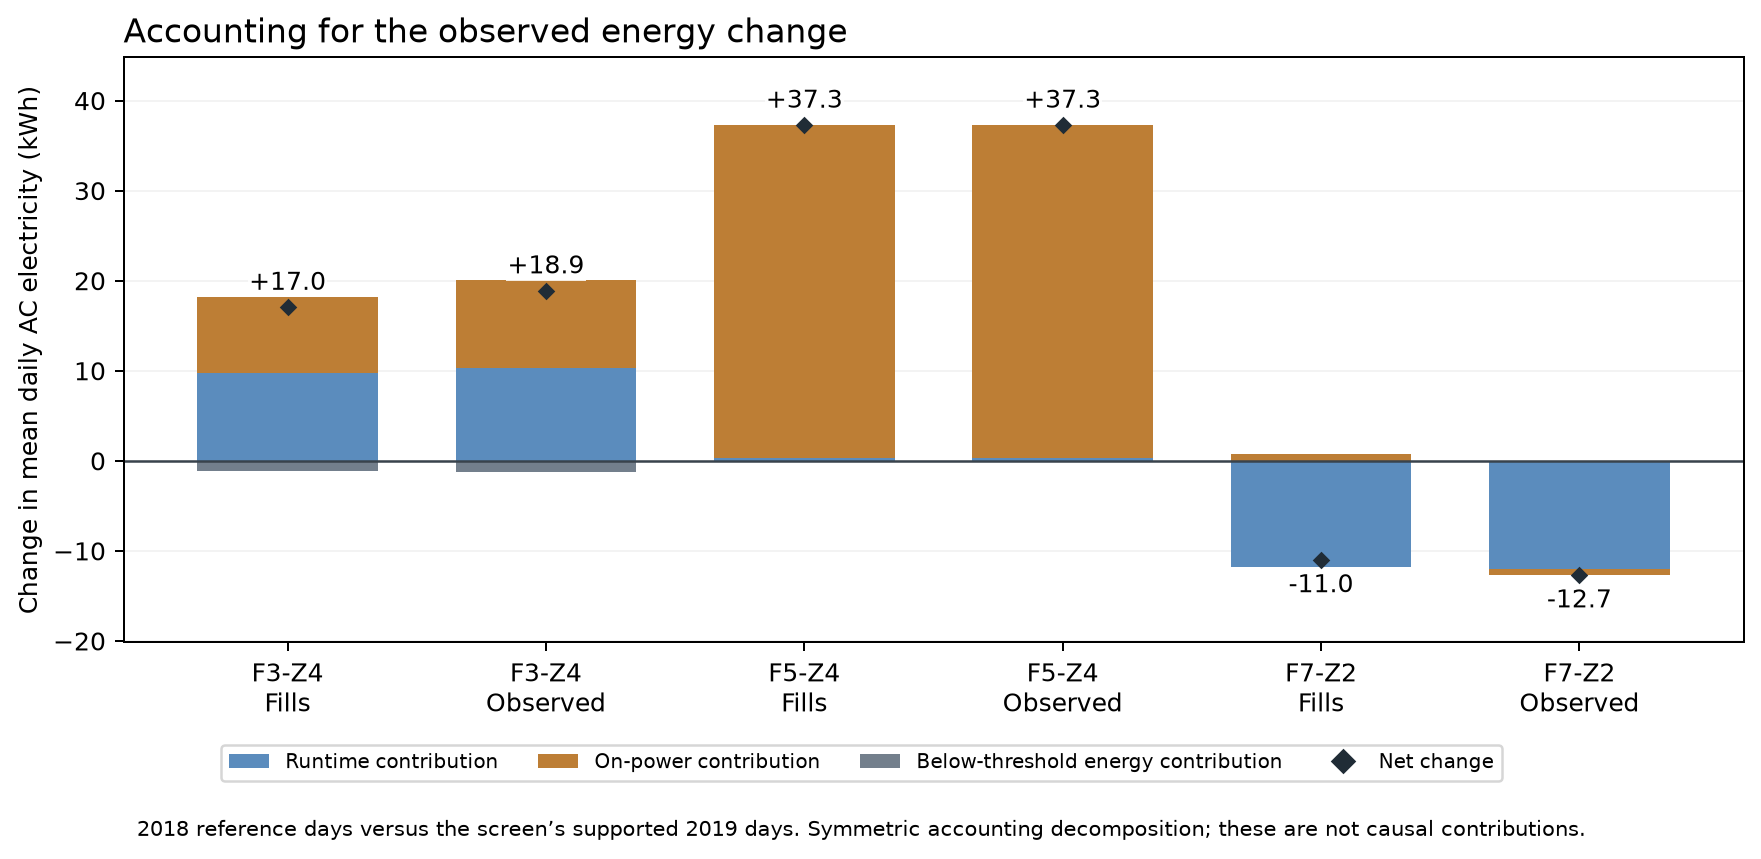

Saved case_conclusions.csv with complete reporting language and attribution limits.


In [5]:
case.plot_cases(data, decomposition, output_dir)
display(Image(filename=str(output_dir / "operating_profiles.png")))
display(Image(filename=str(output_dir / "energy_contributions.png")))
reportable = case.conclusions(output_dir)
print("Saved case_conclusions.csv with complete reporting language and attribution limits.")


## Recommended reporting language and follow-up

**F3-Z4:** “F3-Z4 shows a change in metered AC operation, with increased on-time and on-power. Environmental year comparisons remain sensitive to an unresolved baseline shift, so AC degradation cannot be confirmed.”

**F5-Z4:** “F5-Z4 used more electricity mainly through higher power during operation rather than longer runtime. This warrants control/load and metering checks; the data do not establish AC degradation or actual overcooling.”

**F7-Z2:** “F7-Z2 shows higher recorded moisture during sustained AC operation and a weaker day-versus-night cooling association. The pattern warrants joint sensor, operating-condition and AC checks; physical degradation remains unconfirmed.”

Obtain sensor identity/calibration/placement and firmware history, control/setpoint and equipment-change records, ventilation/moisture-load information, and maintenance/airflow/coil/condensate measurements where available. These records would distinguish the competing mechanisms. No refrigerant fault, drain leak, mould condition, efficiency change or remaining life is confirmed by this analysis. The partner's Track A implementation and the joint risk matrix remain separate.


In [6]:
# Verification focuses on accounting, cohort identity, matching, scenario construction and source integrity.
assert set(data["hourly"].zone_id) == {"F3-Z4", "F5-Z4", "F7-Z2"}
assert data["hourly"].time.dt.month.isin([7, 8]).all()
assert data["hourly"].time.dt.year.isin([2018, 2019]).all()
np.testing.assert_allclose(decomposition.energy_change_kWh,
    decomposition.runtime_contribution_kWh + decomposition.power_contribution_kWh + decomposition.off_contribution_kWh, atol=1e-8)
assert decomposition.query("zone_id == 'F5-Z4'").power_share_of_change_pct.between(99, 100).all()
assert matching["matched_details"].candidate_reference_hours.ge(3).all()
assert primary.query("zone_id == 'F7-Z2' and state == 'steady_on' and metric == 'indoor_w_gkg'").mean_change.between(.9, 1.4).all()
# A common additive temperature correction changes each state's residual equally, so cancels in their contrast.
a = matching["matched_details"].copy()
a["change_temp_C"] = a.change_temp_C + 7
for (zone, variant), g in a.groupby(["zone_id", "variant"]):
    original = matching["matched_details"].query("zone_id == @zone and variant == @variant")
    dates = g.query("state == 'steady_on'").date.unique()
    def contrast(frame):
        pivot = frame.groupby(["date", "state"]).change_temp_C.mean().unstack()
        return (pivot.steady_on - pivot.night_off).dropna().mean()
    np.testing.assert_allclose(contrast(g), contrast(original), atol=1e-9)
for path, h in previous_hashes.items(): assert screen.digest(Path(path)) == h, path
manifest = json.loads((output_dir / "input_manifest.json").read_text())
for item in manifest: assert screen.digest(repo_root / item["path"]) == item["sha256"]
publication = {"doi": "10.1038/s41597-020-00582-3", "url": "https://pmc.ncbi.nlm.nih.gov/articles/PMC7371880/",
               "mounting": "ceiling", "firmware_maintenance_interval": "2018-09-15 to 2019-03-05",
               "nominal_design_temperature_accuracy_C": .4, "nominal_design_RH_accuracy_pp": 2,
               "caution": "Design values do not verify per-period field calibration; scenarios are not measured bias."}
(output_dir / "publication_context.json").write_text(json.dumps(publication, indent=2) + "\n")
report = {"scope": "F3-Z4, F5-Z4, F7-Z2; July-August 2018/2019; with/without existing fills",
          "source_manifest": "input_manifest.json", "protected_previous_files": len(previous_hashes),
          "code_sha256": screen.digest(Path(case.__file__)),
          "matching": "Same hour/state; 1 C outdoor T, 1 g/kg outdoor w; 2018-based plug caliper; >=3 reference dates",
          "matching_sensitivity": [.5, 1, 1.5], "new_comparisons": "Descriptive; no new causal/inferential intervals",
          "long_off_control": "At least 24 uninterrupted hours with valid AC power <=0.1 kW; overlaps other states",
          "versions": {p: metadata.version(p) for p in ["pandas", "numpy", "matplotlib"]},
          "mechanical_degradation_confirmed": False}
(output_dir / "summary.json").write_text(json.dumps(report, indent=2) + "\n")
print(f"Passed: original energy targets, exact decomposition, matching, offset algebra and {len(manifest)} input hashes.")
print(f"All {len(previous_hashes)} prior evidence files unchanged. Focused conclusions saved.")


Passed: original energy targets, exact decomposition, matching, offset algebra and 18 input hashes.
All 65 prior evidence files unchanged. Focused conclusions saved.
